# 03 — Feature Engineering

Fitur adalah kolom turunan yang membantu analisis, misalnya return harian, moving average,
drawdown, dan volatilitas bergulir.

Aturan penting: **jangan memakai informasi masa depan**. Moving average hari ini hanya
boleh memakai harga sampai hari ini.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if (ROOT / "notebooks").exists():
    pass
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("Root proyek:", ROOT)

Root proyek: C:\Users\53\Documents\data sains\project saham


In [2]:
from src.data_loader import load_historical_prices
from src.data_cleaning import clean_historical
from src.feature_engineering import build_daily_features, save_daily_features

prices = clean_historical(load_historical_prices())
features = build_daily_features(prices)
print("Ukuran fitur:", features.shape)
features.head(3)

Ukuran fitur: (23856, 16)


,date,ticker,open,high,low,close,adj_close,volume,ohlc_valid,daily_return,cumulative_return,drawdown,ma_20,ma_50,ma_200,rolling_vol_20
0,2019-01-01,ADRO.JK,1215.0,1215.0,1215.0,1215.0,318.382202,0,True,NaN,0.000000,0.0,NaN,NaN,NaN,NaN
1,2019-01-02,ADRO.JK,1215.0,1225.0,1215.0,1225.0,321.002655,17086200,True,0.008231,0.008231,0.0,NaN,NaN,NaN,NaN
2,2019-01-03,ADRO.JK,1225.0,1235.0,1215.0,1230.0,322.312866,26738400,True,0.004082,0.012346,0.0,NaN,NaN,NaN,NaN


## 1. Kolom yang dibuat

In [3]:
for column in [
    "daily_return", "cumulative_return", "drawdown",
    "ma_20", "ma_50", "ma_200", "rolling_vol_20",
]:
    print(f"{column:20s} | non-null: {features[column].notna().sum():6d} | contoh: {features[column].dropna().head(1).tolist()}")

daily_return         | non-null:  23843 | contoh: [0.008230525648659448]
cumulative_return    | non-null:  23856 | contoh: [0.0]
drawdown             | non-null:  23856 | contoh: [0.0]
ma_20                | non-null:  23609 | contoh: [363.78113708496096]
ma_50                | non-null:  23219 | contoh: [356.58806579589844]
ma_200               | non-null:  21269 | contoh: [348.4285655212402]
rolling_vol_20       | non-null:  23596 | contoh: [0.5401341816283705]


## 2. Moving average: hanya melihat ke belakang

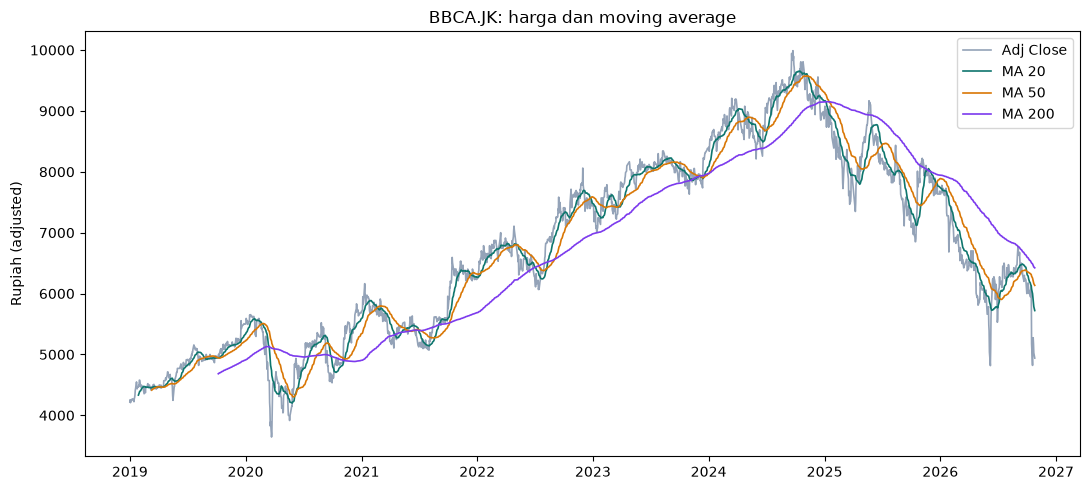

In [4]:
ticker = "BBCA.JK"
subset = features[features["ticker"] == ticker].set_index("date")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(subset.index, subset["adj_close"], label="Adj Close", color="#94A3B8", linewidth=1.2)
ax.plot(subset.index, subset["ma_20"], label="MA 20", color="#0F766E", linewidth=1.2)
ax.plot(subset.index, subset["ma_50"], label="MA 50", color="#D97706", linewidth=1.2)
ax.plot(subset.index, subset["ma_200"], label="MA 200", color="#7C3AED", linewidth=1.2)
ax.set_title(f"{ticker}: harga dan moving average")
ax.set_ylabel("Rupiah (adjusted)")
ax.legend()
plt.tight_layout()
plt.show()

**Cara membaca:** MA 20 lebih reaktif, MA 200 lebih halus. Perpotongan garis bukan
sinyal pasti. Moving average adalah ringkasan masa lalu, bukan ramalan.

## 3. Volatilitas bergulir dan drawdown

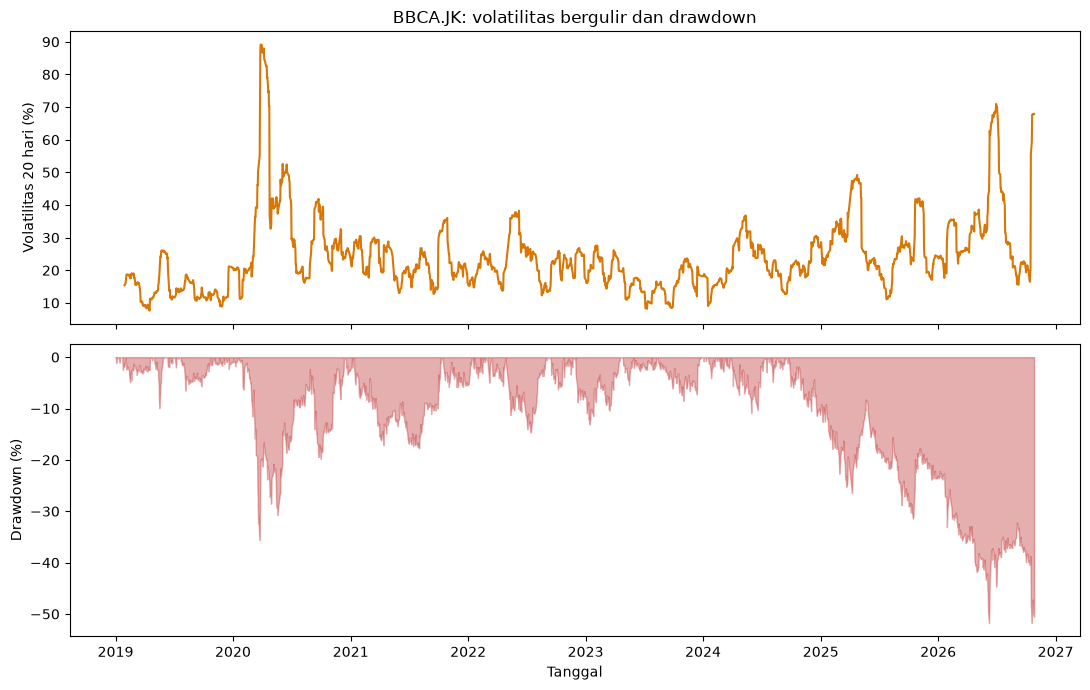

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(subset.index, subset["rolling_vol_20"] * 100, color="#D97706")
axes[0].set_ylabel("Volatilitas 20 hari (%)")
axes[0].set_title(f"{ticker}: volatilitas bergulir dan drawdown")
axes[1].fill_between(subset.index, subset["drawdown"] * 100, 0, color="#B91C1C", alpha=0.35)
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Tanggal")
plt.tight_layout()
plt.show()

In [6]:
summary = features.groupby("ticker").agg(
    observasi=("date", "nunique"),
    return_harian_rata=("daily_return", "mean"),
    vol_harian=("daily_return", "std"),
    drawdown_terdalam=("drawdown", "min"),
).sort_values("drawdown_terdalam")
summary

,observasi,return_harian_rata,vol_harian,drawdown_terdalam
ticker,,,,
GOTO.JK,1085,-0.001780,0.038670,-0.940594
SMGR.JK,1899,-0.000612,0.027597,-0.893108
UNVR.JK,1899,-0.000514,0.024047,-0.876301
AKRA.JK,1899,0.000858,0.026603,-0.729430
ANTM.JK,1899,0.001326,0.031950,-0.702564
ASII.JK,1898,0.000168,0.020936,-0.601237
ADRO.JK,1898,0.001481,0.028532,-0.592420
BBRI.JK,1899,0.000376,0.020860,-0.524335
BMRI.JK,1899,0.000511,0.021383,-0.520507


## 4. Simpan fitur harian

In [7]:
saved = save_daily_features(prices)
print("Disimpan:", len(saved), "baris")
print(saved[["date", "ticker", "daily_return", "ma_20", "drawdown"]].tail(3))

Disimpan: 23856 baris
            date ticker  daily_return        ma_20  drawdown
23853 2026-10-22  ^JKSE      0.011175  5852.916333 -0.410172
23854 2026-10-23  ^JKSE      0.009531  5812.784619 -0.404550
23855 2026-10-26  ^JKSE     -0.012164  5774.046387 -0.411793


## Kesimpulan

- Fitur dibuat dari data yang sudah dibersihkan.
- `rolling_vol_20` dan moving average memakai jendela waktu, bukan seluruh data.
- Drawdown dihitung dari puncak sebelumnya.
- File fitur disimpan di `data/processed/daily_features.csv`.

Lanjut ke `04_eda.ipynb` untuk analisis eksploratif.